In [30]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path

print("All libraries imported successfully!")



All libraries imported successfully!


In [31]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [33]:
# Find the project folder
BASE_DIR = Path.cwd()

if not (BASE_DIR / "data" / "boutique.db").exists():
    BASE_DIR = BASE_DIR.parent

# Connect to the SQLite database
DB_FILE = BASE_DIR / "data" / "boutique.db"

connection = sqlite3.connect(DB_FILE)

# Load transaction data
df = pd.read_sql_query("SELECT * FROM transactions", connection)

connection.close()

# Display the results
print("Database connected successfully!")
print("Total transactions:", len(df))

display(df.head())

Database connected successfully!
Total transactions: 150


,date,id,amount,category,customer_id
0,2026-02-27,T001,909,Bags,C016
1,2026-04-25,T002,2786,Dresses,C044
2,2026-10-07,T003,1924,Accessories,C028
3,2026-01-17,T004,988,Dresses,C014
4,2026-04-30,T005,8779,Accessories,C002


In [34]:
# Convert date column into datetime format
df["date"] = pd.to_datetime(df["date"])

# Check dataset size
print("Dataset shape:", df.shape)

# Check column information
print("\nDataset information:")
df.info()

# Check missing values
print("\nMissing values:")
display(df.isnull().sum())

# View statistical summary
print("\nStatistical summary:")
display(df.describe())


Dataset shape: (150, 5)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         150 non-null    datetime64[us]
 1   id           150 non-null    str           
 2   amount       150 non-null    int64         
 3   category     150 non-null    str           
 4   customer_id  150 non-null    str           
dtypes: datetime64[us](1), int64(1), str(3)
memory usage: 6.0 KB

Missing values:


date           0
id             0
amount         0
category       0
customer_id    0
dtype: int64


Statistical summary:


,date,amount
count,150,150.000000
mean,2026-05-27 11:40:48,9370.740000
min,2026-01-01 00:00:00,509.000000
25%,2026-02-27 12:00:00,3703.000000
50%,2026-05-25 00:00:00,7644.500000
75%,2026-08-11 06:00:00,11588.250000
max,2026-10-26 00:00:00,120000.000000
std,NaN,13871.218309


In [35]:

# Load and execute the three SQL business queries

SQL_FILE = BASE_DIR / "sql" / "business_questions.sql"

with open(SQL_FILE, "r", encoding="utf-8") as file:
    sql_script = file.read()

queries = [q.strip() for q in sql_script.split(";") if q.strip()]

connection = sqlite3.connect(DB_FILE)

monthly_sales_sql = pd.read_sql_query(queries[0], connection)
category_sales_sql = pd.read_sql_query(queries[1], connection)
customer_spending_sql = pd.read_sql_query(queries[2], connection)

connection.close()

print("SQL queries executed successfully!")

print("\nQUESTION 1: Monthly Sales")
display(monthly_sales_sql)

print("\nQUESTION 2: Sales by Product Category")
display(category_sales_sql)

print("\nQUESTION 3: Average Spending Per Customer")
display(customer_spending_sql)


SQL queries executed successfully!

QUESTION 1: Monthly Sales


,month,total_sales
0,2026-01,164670
1,2026-02,355493
2,2026-03,73951
3,2026-04,88827
4,2026-05,190787
5,2026-06,148422
6,2026-07,91549
7,2026-08,102544
8,2026-09,104454
9,2026-10,84914



QUESTION 2: Sales by Product Category


,category,total_sales
0,Shoes,376037
1,Jewelry,296818
2,Dresses,280172
3,Bags,275163
4,Accessories,177421



QUESTION 3: Average Spending Per Customer


,customer_id,average_spend,total_transactions
0,C040,47874.33,3
1,C033,24855.40,5
2,C023,23505.25,4
3,C013,13730.00,1
4,C011,12846.00,1
5,C038,12003.50,2
6,C022,11376.00,1
7,C039,11218.00,3
8,C001,11184.00,1
9,C049,10930.00,2


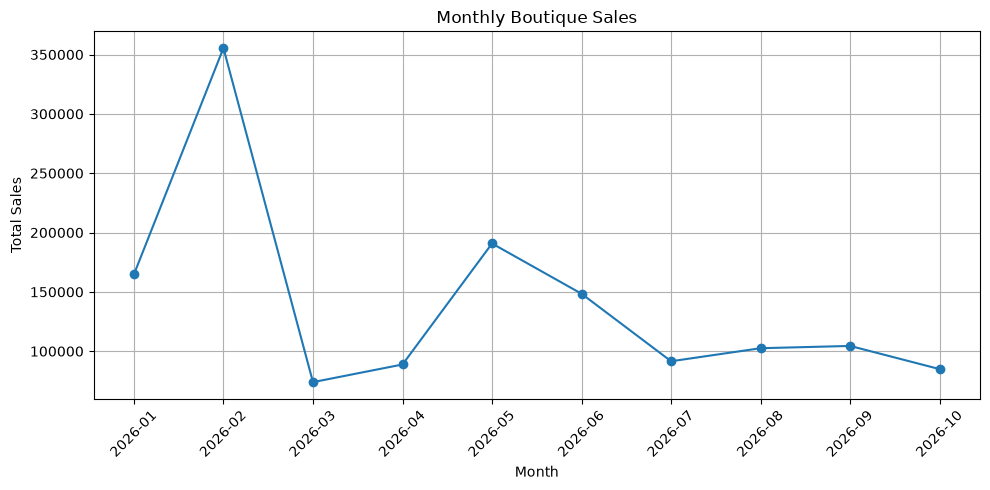

In [36]:
# Chart 1: Monthly Sales (SQL Results)

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales_sql["month"],
    monthly_sales_sql["total_sales"],
    marker="o"
)

plt.title("Monthly Boutique Sales")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

CHART_DIR = BASE_DIR / "reports" / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

plt.savefig(CHART_DIR / "monthly_sales.png")
plt.show()

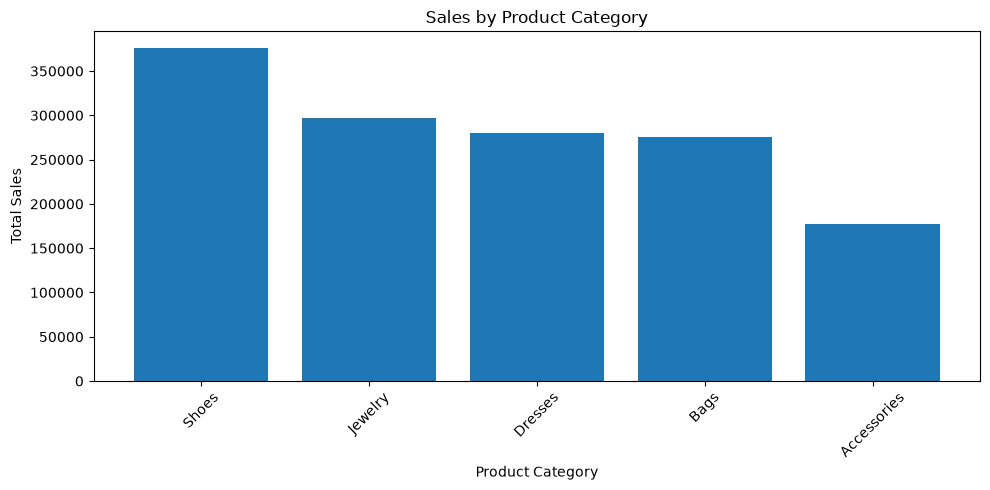

In [37]:
# Chart 2: Sales by Product Category (SQL Results)

plt.figure(figsize=(10, 5))

plt.bar(
    category_sales_sql["category"],
    category_sales_sql["total_sales"]
)

plt.title("Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(CHART_DIR / "category_sales.png")
plt.show()

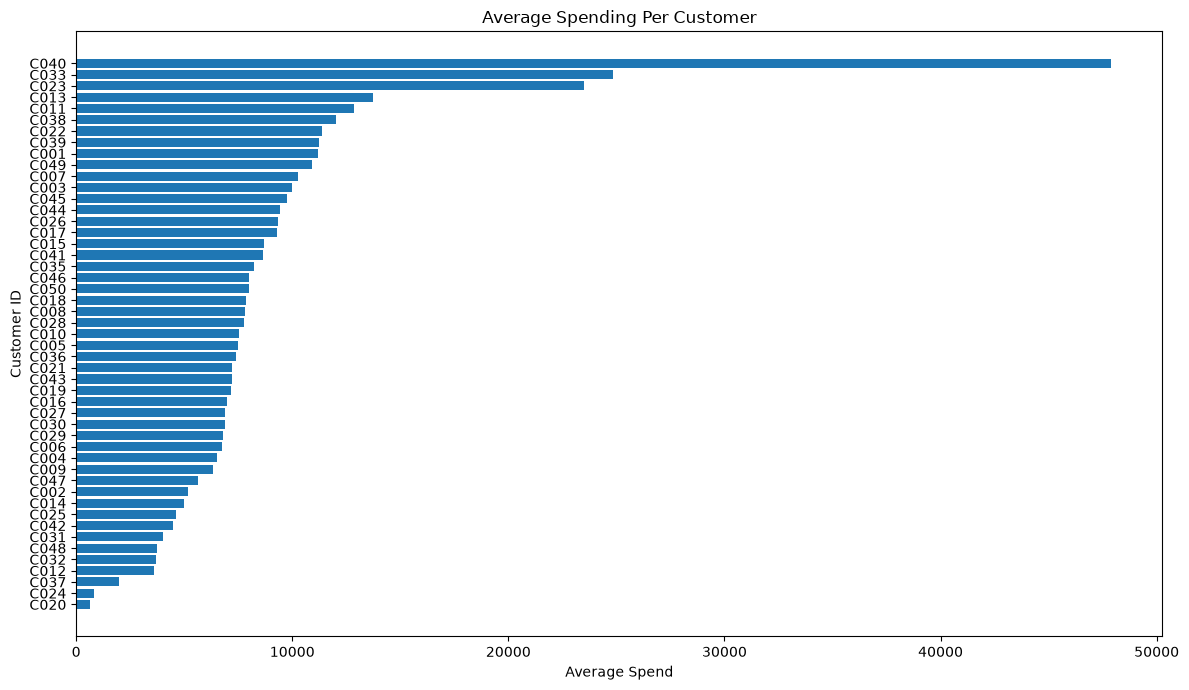

In [38]:
# Chart 3: Average Spending Per Customer (SQL Results)

plt.figure(figsize=(12, 7))

plt.barh(
    customer_spending_sql["customer_id"],
    customer_spending_sql["average_spend"]
)

plt.title("Average Spending Per Customer")
plt.xlabel("Average Spend")
plt.ylabel("Customer ID")
plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(CHART_DIR / "customer_spending.png")
plt.show()